In [ ]:
!pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

# Load the dataset
dataset = fetch_ucirepo(id=468)

# Separate features and target
X = dataset.data.features
y = dataset.data.targets

# Combine them into one DataFrame
df = pd.concat([X, y], axis=1)

In [ ]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [ ]:
df.shape

(12330, 18)

In [ ]:
df.columns

Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType',
       'Weekend', 'Revenue'],
      dtype='object')

In [ ]:
df.info

<bound method DataFrame.info of        Administrative  Administrative_Duration  Informational  \
0                   0                      0.0              0   
1                   0                      0.0              0   
2                   0                      0.0              0   
3                   0                      0.0              0   
4                   0                      0.0              0   
...               ...                      ...            ...   
12325               3                    145.0              0   
12326               0                      0.0              0   
12327               0                      0.0              0   
12328               4                     75.0              0   
12329               0                      0.0              0   

       Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                         0.0               1                 0.000000   
1                         0.0               2                64.000000   
2                         0.0               1                 0.000000   
3                         0.0               2                 2.666667   
4                         0.0              10               627.500000   
...                       ...             ...                      ...   
12325                     0.0              53              1783.791667   
12326                     0.0               5               465.750000   
12327                     0.0               6               184.250000   
12328                     0.0              15               346.000000   
12329                     0.0               3                21.250000   

       BounceRates  ExitRates  PageValues  SpecialDay Month  OperatingSystems  \
0         0.200000   0.200000    0.000000         0.0   Feb                 1   
1         0.000000   0.100000    0.000000         0.0   Feb                 2   
2         0.200000   0.200000    0.000000         0.0   Feb                 4   
3         0.050000   0.140000    0.000000         0.0   Feb                 3   
4         0.020000   0.050000    0.000000         0.0   Feb                 3   
...            ...        ...         ...         ...   ...               ...   
12325     0.007143   0.029031   12.241717         0.0   Dec                 4   
12326     0.000000   0.021333    0.000000         0.0   Nov                 3   
12327     0.083333   0.086667    0.000000         0.0   Nov                 3   
12328     0.000000   0.021053    0.000000         0.0   Nov                 2   
12329     0.000000   0.066667    0.000000         0.0   Nov                 3   

       Browser  Region  TrafficType        VisitorType  Weekend  Revenue  
0            1       1            1  Returning_Visitor    False    False  
1            2       1            2  Returning_Visitor    False    False  
2            1       9            3  Returning_Visitor    False    False  
3            2       2            4  Returning_Visitor    False    False  
4            3       1            4  Returning_Visitor     True    False  
...        ...     ...          ...                ...      ...      ...  
12325        6       1            1  Returning_Visitor     True    False  
12326        2       1            8  Returning_Visitor     True    False  
12327        2       1           13  Returning_Visitor     True    False  
12328        2       3           11  Returning_Visitor    False    False  
12329        2       1            2        New_Visitor     True    False  

[12330 rows x 18 columns]>

In [ ]:
df['Revenue'].value_counts()

,count
Revenue,
False,10422
True,1908


In [ ]:
df['Revenue'].value_counts(normalize=True)

,proportion
Revenue,
False,0.845255
True,0.154745


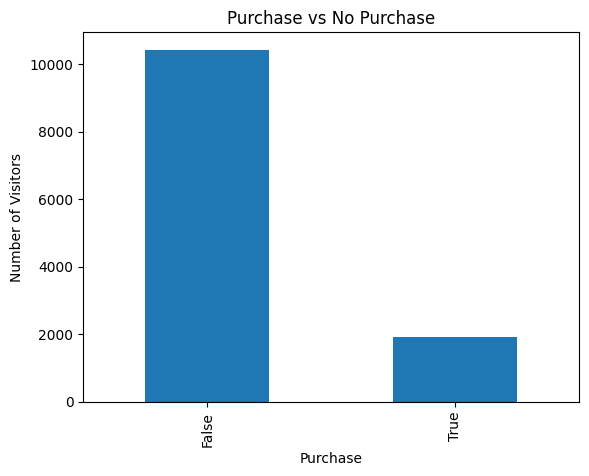

In [ ]:


import matplotlib.pyplot as plt
df['Revenue'].value_counts().plot(
    kind='bar',
    title='Purchase vs No Purchase'
)

plt.xlabel('Purchase')
plt.ylabel('Number of Visitors')
plt.show()


In [ ]:
print("Purchase Analysis:")
print(df['Revenue'].value_counts())

print("\nPercentages:")
print(df['Revenue'].value_counts(normalize=True) * 100)

Purchase Analysis:
Revenue
False    10422
True      1908
Name: count, dtype: int64

Percentages:
Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64


Exploratory Data Analysis (EDA)

1. Purchase Distribution Analysis

The dataset contains 12,330 shopping sessions.

• 10,422 sessions (84.53%) resulted in no purchase.
• 1,908 sessions (15.47%) resulted in a purchase.

Conclusion

The dataset is imbalanced because the number of non-purchasing sessions is significantly higher than the number of purchasing sessions.

Therefore, we should use appropriate evaluation metrics such as Precision, Recall, and F1-score instead of relying only on Accuracy.

In [ ]:
df.groupby('Revenue')['ProductRelated_Duration'].mean()

,ProductRelated_Duration
Revenue,
False,1069.987809
True,1876.209615


In [ ]:
df.groupby('Revenue')['ProductRelated_Duration'].mean()

,ProductRelated_Duration
Revenue,
False,1069.987809
True,1876.209615


In [ ]:
df.groupby('Revenue')['ProductRelated_Duration'].median()

,ProductRelated_Duration
Revenue,
False,510.19000
True,1109.90625


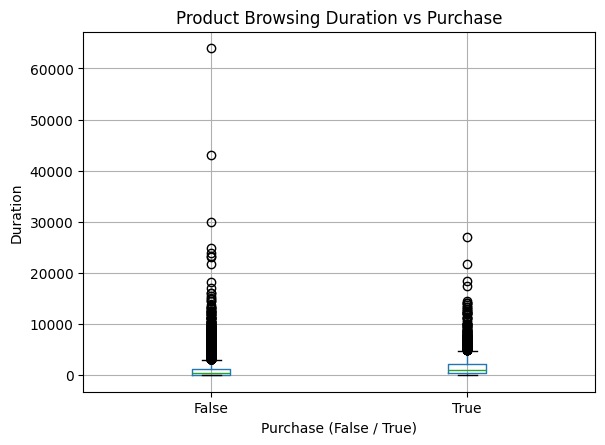

In [ ]:
import matplotlib.pyplot as plt

df.boxplot(
    column='ProductRelated_Duration',
    by='Revenue'
)

plt.title('Product Browsing Duration vs Purchase')
plt.suptitle('')
plt.xlabel('Purchase (False / True)')
plt.ylabel('Duration')
plt.show()

In [ ]:
print(df.groupby('Revenue')['ProductRelated_Duration'].agg(['mean', 'median', 'max', 'count']))

                mean      median          max  count
Revenue                                             
False    1069.987809   510.19000  63973.52223  10422
True     1876.209615  1109.90625  27009.85943   1908


2. Product Browsing Duration Analysis

We analyzed the relationship between ProductRelated_Duration and Revenue.

• The average browsing duration is approximately 1869.99 seconds for non-buyers and 1876.29 seconds for buyers.
• The median browsing duration is 510.19 seconds for non-buyers and 1109.91 seconds for buyers.
• The maximum browsing duration is higher among non-buyers.

Conclusion

Buyers have a higher median product browsing duration than non-buyers, while the mean values are very similar. This suggests that browsing duration may provide useful information about purchasing behavior. However, ProductRelated_Duration alone is not sufficient to predict whether a visitor will make a purchase.

In [ ]:
df.groupby('Revenue')['PageValues'].agg(['mean', 'median', 'max', 'count'])

,mean,median,max,count
Revenue,,,,
False,1.975998,0.000000,246.758590,10422
True,27.264518,16.758134,361.763742,1908


 PageValues Analysis

We analyzed the relationship between PageValues and Revenue.

• The mean PageValues for non-buyers is approximately 1.98.
• The mean PageValues for buyers is approximately 27.26.
• The median PageValues for non-buyers is 0, while the median for buyers is approximately 16.76.

Conclusion

Visitors who made a purchase generally had higher PageValues than visitors who did not purchase. This suggests that PageValues may be an important feature for predicting purchasing behavior.

In [ ]:
print(df.isnull().sum())

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


In [ ]:
print("Number of dublicate rows:", df.duplicated().sum())

Number of dublicate rows: 125


In [ ]:
df=df.drop_duplicates()

In [ ]:
print("Shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Shape after removing duplicates: (12205, 18)
Remaining duplicates: 0


In [ ]:
X = df.drop('Revenue', axis=1)
y = df['Revenue']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (12205, 17)
Target shape: (12205,)


In [ ]:
print(X.select_dtypes(include=['object']).columns)

Index(['Month', 'VisitorType'], dtype='object')


In [ ]:
X = pd.get_dummies(X, columns=['Month', 'VisitorType'], drop_first=True, dtype=int)

print(X.shape)
print(X.head())

(12205, 26)
   Administrative  Administrative_Duration  Informational  \
0               0                      0.0              0   
1               0                      0.0              0   
2               0                      0.0              0   
3               0                      0.0              0   
4               0                      0.0              0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0               1                 0.000000   
1                     0.0               2                64.000000   
2                     0.0               1                 0.000000   
3                     0.0               2                 2.666667   
4                     0.0              10               627.500000   

   BounceRates  ExitRates  PageValues  SpecialDay  ...  Month_Feb  Month_Jul  \
0         0.20       0.20         0.0         0.0  ...          1          0   
1         0.00       0.10         0.0   

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (9764, 26)
Testing data: (2441, 26)


In [ ]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [ ]:
y_pred = model.predict(X_test)

print("Predictions completed!")

Predictions completed!


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.902498975829578

Classification Report:
              precision    recall  f1-score   support

       False       0.92      0.97      0.94      2059
        True       0.75      0.57      0.64       382

    accuracy                           0.90      2441
   macro avg       0.84      0.77      0.79      2441
weighted avg       0.90      0.90      0.90      2441


Confusion Matrix:
[[1987   72]
 [ 166  216]]


 Model Evaluation

We evaluated the Random Forest model using Accuracy, Precision, Recall, F1-score, and Confusion Matrix.

• The model achieved approximately 90% accuracy.
• The Precision for buyers was 75%.
• The Recall for buyers was 57%.
• The F1-score for buyers was 64%.

Conclusion

The model performs well in identifying non-purchasing visitors, but it has difficulty detecting some purchasing visitors. This is likely related to the imbalanced nature of the dataset.

Further model optimization is needed to improve the detection of purchasing visitors.

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

params = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'class_weight': ['balanced', 'balanced_subsample']
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    params,
    scoring='recall',
    cv=3,
    n_jobs=-1
)

grid.fit(X_train, y_train)

best_model = grid.best_estimator_

print("Best Parameters:", grid.best_params_)
print("Best Cross-Validation Recall:", grid.best_score_)

Best Parameters: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}
Best Cross-Validation Recall: 0.781775804547025


In [ ]:
y_pred_tuned = best_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

Accuracy: 0.8779188857025809

Classification Report:
              precision    recall  f1-score   support

       False       0.96      0.89      0.93      2059
        True       0.58      0.79      0.67       382

    accuracy                           0.88      2441
   macro avg       0.77      0.84      0.80      2441
weighted avg       0.90      0.88      0.89      2441


Confusion Matrix:
[[1840  219]
 [  79  303]]


In [ ]:
import joblib

model_bundle = {
    'model': best_model,
    'columns': X.columns.tolist()
}

joblib.dump(model_bundle, 'purchase_prediction_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files

files.download('purchase_prediction_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>